# 03 — Portfolio Optimization

So far we fixed weights by hand (`1/n`). Now we **choose** weights with math.

First goal: **minimum-variance** portfolio — the long-only mix with the smallest estimated bumpiness (volatility), with weights ≥ 0 that sum to 1.

## Concept (read before coding)

Portfolio variance depends on **every pair of stocks**, not just each stock alone:

$$
\sigma_p^2 = w^\top \Sigma w
$$

- $w$ = weights (must sum to 1, each ≥ 0 for long-only)
- $\Sigma$ = covariance matrix of daily returns (how each pair moves together)

**Equal-weight** ignored $\Sigma$. **Min-variance** uses $\Sigma$ and picks $w$ to make $\sigma_p^2$ as small as possible.

We'll solve that with SciPy (`minimize`), then compare weights and risk to equal-weight.

## 1. Setup and returns

Same universe as before. We optimize using **stock** returns only (SPY stays a benchmark for later comparison).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import DEFAULT_BENCHMARK, DEFAULT_TICKERS, load_or_download

TICKERS = DEFAULT_TICKERS
BENCHMARK = DEFAULT_BENCHMARK
TRADING_DAYS = 252

prices = load_or_download(tickers=TICKERS + [BENCHMARK], refresh=False)
stock_returns = prices[TICKERS].pct_change().dropna()

print(stock_returns.shape)
stock_returns.head()

(1716, 9)


,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ
Date,,,,,,,,,
2020-01-03,-0.009722,-0.012452,-0.016006,-0.012139,-0.005456,-0.008828,-0.013197,-0.008039,-0.011578
2020-01-06,0.007968,0.002585,0.004193,0.014886,-0.000366,-0.002036,-0.000795,0.007678,-0.001247
2020-01-07,-0.004702,-0.009118,0.012107,0.002092,-0.007682,-0.009265,-0.017001,-0.008184,0.006107
2020-01-08,0.016086,0.015928,0.001875,-0.007809,0.001843,-0.003432,0.007801,-0.015080,-0.000138
2020-01-09,0.021241,0.012493,0.010982,0.004799,0.018216,0.010330,0.003651,0.007656,0.002966


## 2. Covariance matrix $\Sigma$

Estimate how returns co-move. Diagonal = each stock's own variance; off-diagonal = how pairs move together.

In [2]:
# TODO: estimate covariance + annualized portfolio vol helper

cov_daily = stock_returns.cov()
print("cov shape: ", cov_daily.shape)
display(cov_daily.round(6))

def portfolio_vol(weights, cov, trading_days=252):
    """Annualized volatility from daily cov and weights"""
    w = np.asarray(weights, dtype=float)
    var_daily = w @ cov.values @ w
    return np.sqrt(var_daily * trading_days)

ew = np.repeat(1 / len(TICKERS), len(TICKERS))
print("equal-weight ann vol: {:.2%}".format(portfolio_vol(ew, cov_daily)) )

cov shape:  (9, 9)


,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ
AAPL,0.000384,0.000237,0.000344,0.000234,0.000092,0.000099,0.000152,0.000102,0.000073
MSFT,0.000237,0.000363,0.000385,0.000269,0.000073,0.000079,0.000141,0.000072,0.000053
NVDA,0.000344,0.000385,0.001054,0.000398,0.000047,0.000088,0.000204,0.000096,0.000022
AMZN,0.000234,0.000269,0.000398,0.000503,0.000038,0.000079,0.000122,0.000045,0.000027
KO,0.000092,0.000073,0.000047,0.000038,0.000162,0.000071,0.000105,0.000096,0.000087
WMT,0.000099,0.000079,0.000088,0.000079,0.000071,0.000219,0.000066,0.000047,0.000067
JPM,0.000152,0.000141,0.000204,0.000122,0.000105,0.000066,0.000366,0.000193,0.000080
XOM,0.000102,0.000072,0.000096,0.000045,0.000096,0.000047,0.000193,0.000412,0.000066
JNJ,0.000073,0.000053,0.000022,0.000027,0.000087,0.000067,0.000080,0.000066,0.000157


equal-weight ann vol: 19.74%


## 3. Minimum-variance optimizer

Minimize $w^\top \Sigma w$ subject to $\sum w_i = 1$ and $w_i \ge 0$.

In [4]:
# TODO: scipy minimize for min-variance weights

n = len(TICKERS)
cov = cov_daily.values

def variance_objective(w): # wT sigma w
    return float(w @ cov @ w) # matrix multiplication of weights and cov

constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1.0},)
bounds = tuple((0.0, 1.0) for _ in range(n))
w0 = np.repeat(1/n, n) # start from equal weight

result = minimize(variance_objective, w0, method='SLSQP', 
bounds=bounds, constraints=constraints,
options={"ftol": 1e-14, "maxiter": 1000},  # critical for small daily variances
)

print("success:", result.success, "| message:", result.message)

min_var_weights = pd.Series(result.x, index=TICKERS, name='min_var')
min_var_weights = min_var_weights.clip(lower=0)
min_var_weights = min_var_weights / min_var_weights.sum()


print("weights sum:", min_var_weights.sum().round(6))
print(min_var_weights.round(4).sort_values(ascending=False))
print("min-var ann vol: {:.2%}".format(portfolio_vol(min_var_weights.values, cov_daily)))
print("equal-weight ann vol: {:.2%}".format(portfolio_vol(w0, cov_daily)))

success: True | message: Optimization terminated successfully
weights sum: 1.0
JNJ     0.3388
KO      0.2437
WMT     0.1956
AMZN    0.0996
XOM     0.0857
MSFT    0.0365
AAPL    0.0000
NVDA    0.0000
JPM     0.0000
Name: min_var, dtype: float64
min-var ann vol: 15.68%
equal-weight ann vol: 19.74%


## 4. Compare to equal-weight

Same period for now (in-sample). Later backtests will be the honest test.

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17]),
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, 'AAPL'),
  Text(10, 0, 'MSFT'),
  Text(11, 0, 'NVDA'),
  Text(12, 0, 'AMZN'),
  Text(13, 0, 'KO'),
  Text(14, 0, 'WMT'),
  Text(15, 0, 'JPM'),
  Text(16, 0, 'XOM'),
  Text(17, 0, 'JNJ')])

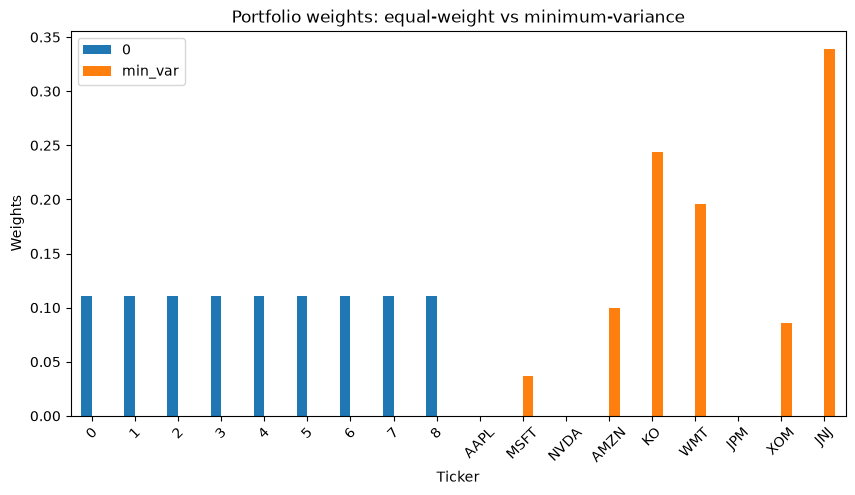

In [6]:
# TODO: weights bar chart + risk comparison

ew_weights = pd.Series(np.repeat(1/len(TICKERS), len(TICKERS)))

weights_df = pd.concat([ew_weights, min_var_weights], axis=1)

ax = weights_df.plot(
    kind='bar', figsize=(10,5), 
    title='Portfolio weights: equal-weight vs minimum-variance',
)

ax.set_ylabel('Weights')
ax.set_xlabel('Ticker')
ax.legend()
plt.xticks(rotation=45)